In [1]:
import pandas as pd

temporadas = [ '1011', '1112', '1213', '1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223', '2324', '2425','2526']
dfs = [pd.read_csv(f"https://www.football-data.co.uk/mmz4281/{t}/SP1.csv") for t in temporadas]
df_laliga_completo = pd.concat(dfs, ignore_index=True)

# 1. Definir la lista exacta de columnas que quieres conservar
columnas_deseadas = [
    # Datos generales del partido
    'Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam',
    
    # Goles y Resultados
    'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR',
    
    # Estadísticas de juego
    'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR'
]

# 2. Filtrar el DataFrame asegurándose de que solo coja las que existen en el archivo
# (Esto evita errores por si alguna columna menor no está en alguna temporada antigua)
columnas_existentes = [col for col in columnas_deseadas if col in df_laliga_completo.columns]

# 3. Definir el diccionario de mapeo (inglés -> español descriptivo)
renombres = {
    # Datos generales del partido
    'Div': 'Division',
    'Date': 'Fecha',
    'Time': 'Hora',
    'HomeTeam': 'Equipo_Local',
    'AwayTeam': 'Equipo_Visitante',
    
    # Goles y Resultados
    'FTHG': 'Goles_Local_Final',
    'FTAG': 'Goles_Visitante_Final',
    'FTR': 'Resultado_Final',
    'HTHG': 'Goles_Local_Descanso',
    'HTAG': 'Goles_Visitante_Descanso',
    'HTR': 'Resultado_Descanso',
    
    # Estadísticas de juego
    'HS': 'Tiros_Totales_Local',
    'AS': 'Tiros_Totales_Visitante',
    'HST': 'Tiros_A_Puerta_Local',
    'AST': 'Tiros_A_Puerta_Visitante',
    'HF': 'Faltas_Cometidas_Local',
    'AF': 'Faltas_Cometidas_Visitante',
    'HC': 'Corners_Local',
    'AC': 'Corners_Visitante',
    'HY': 'Tarjetas_Amarillas_Local',
    'AY': 'Tarjetas_Amarillas_Visitante',
    'HR': 'Tarjetas_Rojas_Local',
    'AR': 'Tarjetas_Rojas_Visitante'
}

# 4. Aplicar el cambio de nombres al DataFrame filtrado
# (Usamos errors='ignore' por si alguna columna no está presente)
df_filtrado = df_laliga_completo[columnas_existentes]
df_espanol = df_filtrado.rename(columns=renombres)

# Verificar las primeras columnas renombradas
print("Nuevos nombres de columnas:")
print(df_espanol.columns.tolist())
print(df_espanol.head(2))

Nuevos nombres de columnas:
['Division', 'Fecha', 'Hora', 'Equipo_Local', 'Equipo_Visitante', 'Goles_Local_Final', 'Goles_Visitante_Final', 'Resultado_Final', 'Goles_Local_Descanso', 'Goles_Visitante_Descanso', 'Resultado_Descanso', 'Tiros_Totales_Local', 'Tiros_Totales_Visitante', 'Tiros_A_Puerta_Local', 'Tiros_A_Puerta_Visitante', 'Faltas_Cometidas_Local', 'Faltas_Cometidas_Visitante', 'Corners_Local', 'Corners_Visitante', 'Tarjetas_Amarillas_Local', 'Tarjetas_Amarillas_Visitante', 'Tarjetas_Rojas_Local', 'Tarjetas_Rojas_Visitante']
  Division     Fecha Hora Equipo_Local Equipo_Visitante  Goles_Local_Final  \
0      SP1  28/08/10  NaN     Hercules       Ath Bilbao                  0   
1      SP1  28/08/10  NaN      Levante          Sevilla                  1   

   Goles_Visitante_Final Resultado_Final  Goles_Local_Descanso  \
0                      1               A                     0   
1                      4               A                     1   

   Goles_Visitante_Descan

In [2]:
# 3. Guardar el resultado en un nuevo archivo CSV en español
df_espanol.to_csv('laliga_espanol_limpio.csv', index=False)

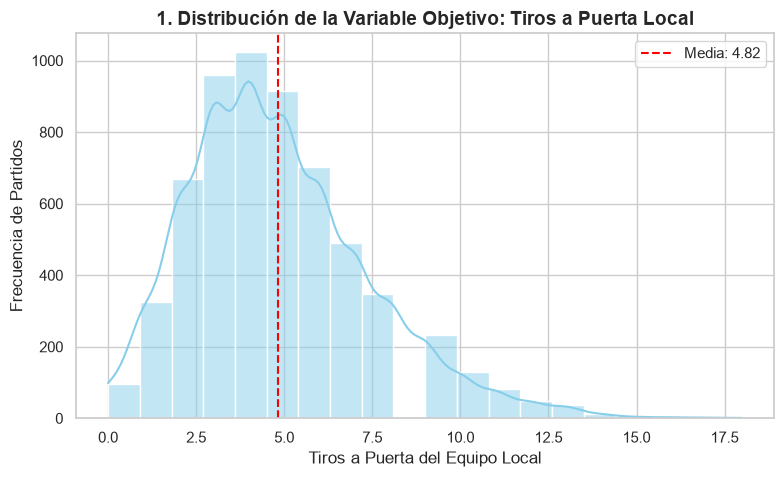

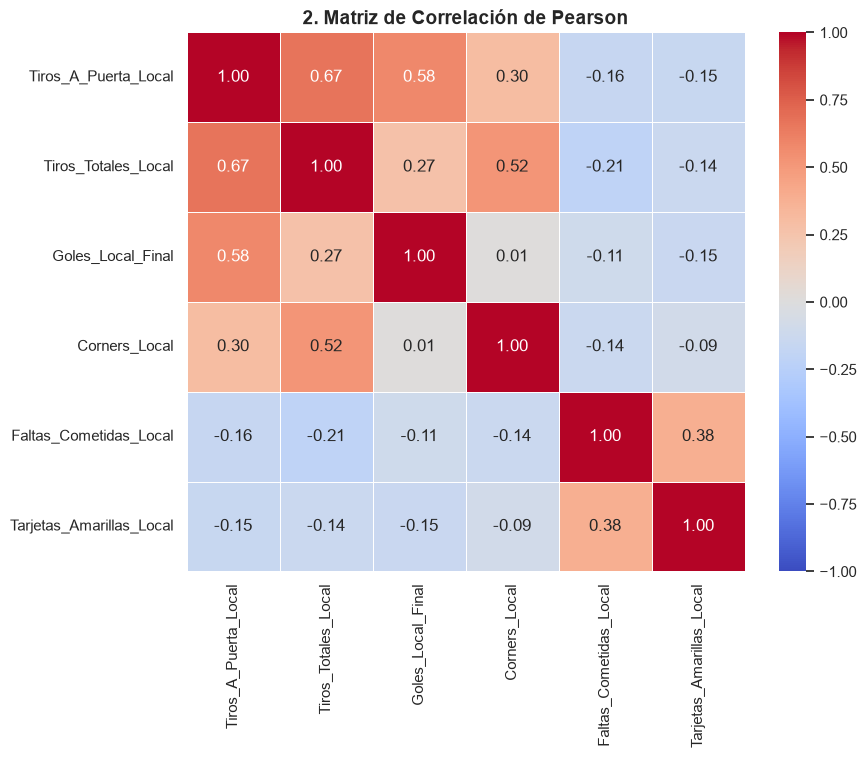

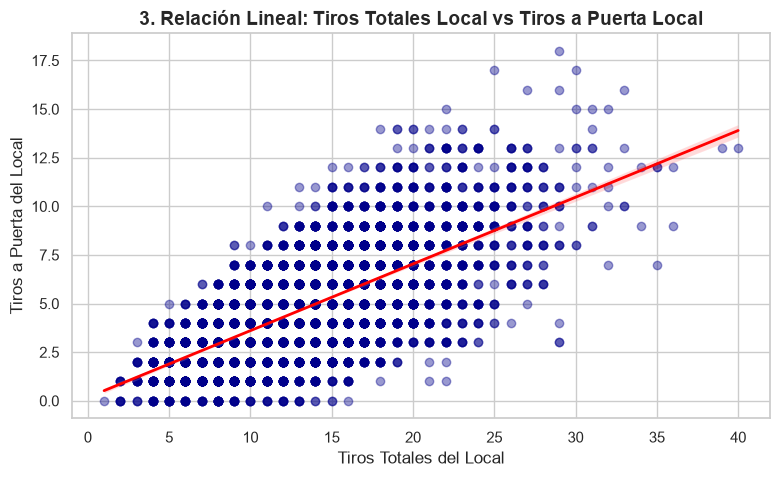

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# PASO EXTRA: CARGAR EL DATASET (Esto soluciona el NameError)
# ==============================================================================
# Usamos el nuevo nombre de archivo .csv que aparece en tu explorador de VS Code
df_espanol = pd.read_csv('laliga_espanol_limpio.csv')

# Configuración inicial de estilos para los gráficos
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. Distribución de la Variable Objetivo (Histograma + KDE)
# ==============================================================================
plt.figure(figsize=(9, 5))
sns.histplot(df_espanol['Tiros_A_Puerta_Local'], kde=True, color='skyblue', bins=20)
plt.title('1. Distribución de la Variable Objetivo: Tiros a Puerta Local', fontsize=14, fontweight='bold')
plt.xlabel('Tiros a Puerta del Equipo Local')
plt.ylabel('Frecuencia de Partidos')
plt.axvline(df_espanol['Tiros_A_Puerta_Local'].mean(), color='red', linestyle='--', label=f"Media: {df_espanol['Tiros_A_Puerta_Local'].mean():.2f}")
plt.legend()
plt.show()

# ==============================================================================
# 2. Matriz de Correlación (Heatmap)
# ==============================================================================
columnas_interes = [
    'Tiros_A_Puerta_Local', 'Tiros_Totales_Local', 'Goles_Local_Final', 
    'Corners_Local', 'Faltas_Cometidas_Local', 'Tarjetas_Amarillas_Local'
]
plt.figure(figsize=(9, 7))
matriz_corr = df_espanol[columnas_interes].corr(method='pearson')
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('2. Matriz de Correlación de Pearson', fontsize=14, fontweight='bold')
plt.show()

# ==============================================================================
# 3. Gráfico de Dispersión con Línea de Tendencia (Scatter Plot + Regresión)
# ==============================================================================
plt.figure(figsize=(9, 5))
sns.regplot(data=df_espanol, x='Tiros_Totales_Local', y='Tiros_A_Puerta_Local', 
            scatter_kws={'alpha':0.4, 'color': 'darkblue'}, line_kws={'color':'red', 'linewidth': 2})
plt.title('3. Relación Lineal: Tiros Totales Local vs Tiros a Puerta Local', fontsize=14, fontweight='bold')
plt.xlabel('Tiros Totales del Local')
plt.ylabel('Tiros a Puerta del Local')
plt.show()
